In [1]:
import numpy as np
from pathlib import Path
from safetensors.numpy import load_file, save_file
from tqdm import tqdm
import argparse
import json
from matplotlib import pyplot as plt
from functools import partial
import scienceplots  # Requires LaTeX

In [2]:
try:
    plt.style.use(['nature', 'science'])  # Match notebook styling
except Exception:
    pass

In [3]:
def make_path(data_path):
    try:
        assert Path.is_dir(data_path) == True
    except AssertionError:
        data_path = Path("..", data_path)
        assert Path.is_dir(data_path) == True, f"{data_path} is not a valid path."
    return data_path

In [4]:
# Model colors - consistent across all plots
MODEL_COLORS = {
    'dino': '#0A5EB0',        # Blue
    'clip_image': '#DC143C',   # Crimson
    'clip_text': '#FF8C00',    # Dark Orange
    'deepseek': '#2E8B57',     # Sea Green
    'igpt': '#399918',          # Green (for future),
    'llama': '#F54927',
    'dino_base' : '#5585A3',
    'dino_small' : '#ACCCE0'
}

# Model display names
MODEL_NAMES = {
    'dino': 'DinoV2',
    'clip_image': 'CLIP-Image',
    'clip_text': 'CLIP-Text',
    'deepseek': 'DeepSeek-V3',
    'igpt': 'ImageGPT',
    'llama': 'LLama3.1-8B'
}

TARGET_LAYERS = {
    'deepseek' : 52,
    'llama' : 20,
    'dino' : 24,
    'clip_text' : 12,
    'igpt' : 20
}

N_LAYERS = {
    'deepseek' : 60,
    'llama' : 32,
    'dino' : 24,
    'igpt' : 48,
    'clip_image' : 24,
    'clip_text' : 12,
    'dino_base' : 12,
    'dino_small': 12
}

In [5]:
def load_inf_imb_data(data_path, n_layers):
    """Load information imbalance data from safetensors files."""
    inf_imb = {}
    for i in range(1, n_layers + 1):
        inf_imb[f"layer_{i}"] = load_file(Path(data_path, f"layer_{i}.safetensors"))
    return inf_imb

In [6]:
def extract_matrices(inf_imb, n_layers):
    """Extract information and multiplicity matrices from loaded data."""
    n_rows = inf_imb.get("layer_1").get('ranks').shape[0]
    
    inf_matrix = np.empty((n_layers, n_rows, 2))
    mult_matrix = np.empty((n_layers, n_rows, 2))
    
    for i in range(n_layers):
        inf_matrix[i, :, 0] = inf_imb[f"layer_{i+1}"]["ranks"]
        inf_matrix[i, :, 1] = inf_imb[f"layer_{i+1}"]["r_ranks"]
        mult_matrix[i, :, 0] = inf_imb[f"layer_{i+1}"]["cards"]
        mult_matrix[i, :, 1] = inf_imb[f"layer_{i+1}"]["r_cards"]
    
    return inf_matrix, mult_matrix, n_rows


def compute_mean_inf_imb(inf_matrix, mult_matrix, n_layers, n_rows, sample_size):
    """Compute mean information imbalance for each layer."""
    n_cols = sample_size - n_rows
    
    # Forward direction
    forward_means = np.zeros(n_layers)
    for i in range(n_layers):
        vals = inf_matrix[i, :, 0]
        cards = mult_matrix[i, :, 0]
        forward_means[i] = 2. * (np.sum(vals) / np.sum(cards)) / (n_cols - 2.)
    
    # Backward direction
    backward_means = np.zeros(n_layers)
    for i in range(n_layers):
        vals = inf_matrix[i, :, 1]
        cards = mult_matrix[i, :, 1]
        backward_means[i] = 2. * (np.sum(vals) / np.sum(cards)) / (n_cols - 2.)
    
    return forward_means, backward_means


def bootstrap(rng, inf_matrix, mult_matrix, n_replicas, bootstrap_size, n_layers, n_rows, sample_size):
    """Perform bootstrap analysis on information imbalance data."""
    n_cols = sample_size - n_rows
    
    inf_forward = np.empty((n_layers, n_replicas))
    inf_backward = np.empty((n_layers, n_replicas))
    
    for layer_id in tqdm(np.arange(n_layers), desc="Bootstrap layers"):
        ranks_forward = inf_matrix[layer_id, :, 0]
        ranks_backward = inf_matrix[layer_id, :, 1]
        cards_forward = mult_matrix[layer_id, :, 0]
        cards_backward = mult_matrix[layer_id, :, 1]
        
        for i in range(n_replicas):
            indices = rng.choice(n_rows, size=bootstrap_size, replace=True)
            inf_forward[layer_id, i] = 2. * (np.sum(ranks_forward[indices]) / np.sum(cards_forward[indices])) / (n_cols - 2.)
            inf_backward[layer_id, i] = 2. * (np.sum(ranks_backward[indices]) / np.sum(cards_backward[indices])) / (n_cols - 2.)
    
    return inf_forward, inf_backward

In [7]:
def save_bootstrap_results(output_path, forward_data, backward_data, config):
    """Save bootstrap results and configuration."""
    # Save numpy arrays
    np.save(Path(output_path, f"{config['model_a']}_{config['model_b']}_{config['layer']}.npy"), forward_data)
    np.save(Path(output_path, f"{config['model_b']}_{config['model_a']}_{config['layer']}.npy"), backward_data)
    
    # Save configuration
    with open(Path(output_path, "bootstrap_config.json"), 'w') as f:
        json.dump(config, f, indent=2)
    
    # Save summary statistics
    summary = {
        'forward_mean': np.mean(forward_data, axis=1).tolist(),
        'forward_std': np.std(forward_data, axis=1).tolist(),
        'backward_mean': np.mean(backward_data, axis=1).tolist(),
        'backward_std': np.std(backward_data, axis=1).tolist(),
        'n_layers': forward_data.shape[0],
        'n_replicas': forward_data.shape[1]
    }
    
    with open(Path(output_path, f"summary_{config['model_a']}_{config['model_b']}.json"), 'w') as f:
        json.dump(summary, f, indent=2)

In [8]:
def make_comparison(to_model, from_model, rng, n_replicas = 100, bootstrap_size = 750, sample_size = 5_000, base_dir=None, hamming=False):
    if base_dir is None:
        base_dir = Path("data", "results-mean")
    AtoB = make_path(Path(base_dir, f"{to_model}_{from_model}", "l2_centered_normalized")) if hamming is False else make_path(Path(base_dir, f"{to_model}_{from_model}", "hamming"))
    print(f"Loading {AtoB}")
    inf_imb = load_inf_imb_data(AtoB, N_LAYERS[from_model])
    inf_matrix, mult_matrix, n_rows = extract_matrices(inf_imb, N_LAYERS[from_model])
    inf_forward, inf_backward = bootstrap(rng, inf_matrix, mult_matrix, n_replicas, bootstrap_size, N_LAYERS[from_model], n_rows, sample_size)
    forward_mean = np.mean(inf_forward, axis=1)
    forward_std = np.std(inf_forward, axis=1)
    backward_mean = np.mean(inf_backward, axis=1)
    backward_std = np.std(inf_backward, axis=1)
    return [forward_mean, forward_std], [backward_mean, backward_std]

In [9]:
rng = np.random.default_rng(2019)
n_replicas = 500
bootstrap_size = 1500
sample_size = 5_000
base_dir = make_path(Path("data", "results-mean"))
assert Path(base_dir).is_dir() == True, f"{base_dir} doesn't exist!"

In [10]:
DO_HAMMING = False

In [11]:
compare_deepseek = partial(make_comparison, to_model="deepseek", rng=rng, base_dir=base_dir, hamming=DO_HAMMING)

In [12]:
igpt_fwd, igpt_bwd = compare_deepseek(from_model="igpt")

Loading ../data/results-mean/deepseek_igpt/l2_centered_normalized


Bootstrap layers: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 48/48 [00:00<00:00, 220.95it/s]


In [13]:
dino_fwd, dino_bwd = compare_deepseek(from_model="dino")

Loading ../data/results-mean/deepseek_dino/l2_centered_normalized


Bootstrap layers: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:00<00:00, 197.53it/s]


In [14]:
llama_fwd, llama_bwd = compare_deepseek(from_model="llama")

Loading ../data/results-mean/deepseek_llama/l2_centered_normalized


Bootstrap layers: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 32/32 [00:00<00:00, 195.72it/s]


In [15]:
dino_igpt_fwd, dino_igpt_bwd = make_comparison(to_model="dino", from_model="igpt", rng=rng, hamming=DO_HAMMING)

Loading ../data/results-mean/dino_igpt/l2_centered_normalized


Bootstrap layers: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 48/48 [00:00<00:00, 209.80it/s]


In [16]:
igpt_dino_fwd, igpt_dino_bwd = make_comparison(to_model="igpt", from_model="dino", rng=rng, hamming=DO_HAMMING)

Loading ../data/results-mean/igpt_dino/l2_centered_normalized


Bootstrap layers: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:00<00:00, 206.70it/s]


In [17]:
imagenet_path = make_path(Path("data", "imagenet"))

In [18]:
imagenet_dino_igpt_fwd = []
imagenet_dino_igpt_fwd.append(np.load(Path(imagenet_path, "cross_dino_to_igpt_mean.npy"))[30, 1:])
imagenet_dino_igpt_fwd.append(np.load(Path(imagenet_path, "cross_dino_to_igpt_std.npy"))[30, 1:])

In [19]:
imagenet_igpt_dino_fwd = []
imagenet_igpt_dino_fwd.append(np.load(Path(imagenet_path, "cross_igpt_to_dino_mean.npy"))[20, 1:])
imagenet_igpt_dino_fwd.append(np.load(Path(imagenet_path, "cross_igpt_to_dino_std.npy"))[20, 1:])

In [20]:
ylim = (0.0, 1)
figsize = (3.5, 3.5)
fontsize_label = 13
x = {key:np.linspace(0, 1, N_LAYERS[key]) for key in N_LAYERS.keys()}

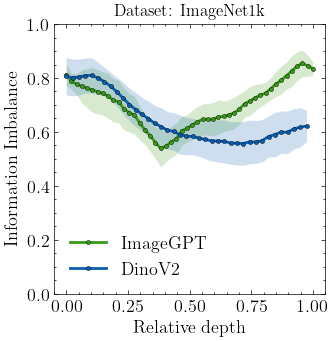

In [21]:
fig, ax = plt.subplots(1, 1, figsize=figsize)

label_forward = f"{MODEL_NAMES['igpt']}"
ax.plot(x['igpt'], imagenet_dino_igpt_fwd[0], '-', color=MODEL_COLORS['igpt'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['igpt'], imagenet_dino_igpt_fwd[0] - imagenet_dino_igpt_fwd[1], imagenet_dino_igpt_fwd[0] + imagenet_dino_igpt_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['igpt'])

label_forward = f"{MODEL_NAMES['dino']}"
ax.plot(np.arange(39)/39, imagenet_igpt_dino_fwd[0], '-', color=MODEL_COLORS['dino'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(np.arange(39)/39, imagenet_igpt_dino_fwd[0] - imagenet_igpt_dino_fwd[1], imagenet_igpt_dino_fwd[0] + imagenet_igpt_dino_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])

title = f"Dataset: ImageNet1k"
ax.set_title(title, fontsize=12)
ax.set_xlabel("Relative depth", fontsize=fontsize_label)
ax.set_ylabel("Information Imbalance", fontsize=fontsize_label)
ax.tick_params(axis='both', labelsize=fontsize_label)
ax.set_ylim(ylim)
ax.legend(fontsize=fontsize_label, loc='best')
plt.savefig(Path("/home/masca/GitHub/deepseek-hidden-states/plots/fig4a.pdf"), dpi = 300)

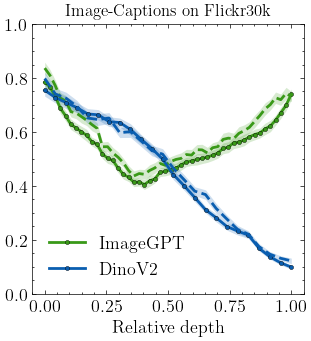

In [22]:
fig, ax = plt.subplots(1, 1, figsize=figsize)

label_forward = f"{MODEL_NAMES['igpt']}"
ax.plot(x['igpt'], igpt_fwd[0], '-', color=MODEL_COLORS['igpt'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['igpt'], igpt_fwd[0] - igpt_fwd[1], igpt_fwd[0] + igpt_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['igpt'])
label_backward = f"{MODEL_NAMES['igpt']} → {MODEL_NAMES['deepseek']}"
ax.plot(x['igpt'], igpt_bwd[0], '--', color=MODEL_COLORS['igpt'], linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['igpt'], igpt_bwd[0] - igpt_bwd[1], igpt_bwd[0] + igpt_bwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['igpt'])

label_forward = f"{MODEL_NAMES['dino']}"
ax.plot(x['dino'], dino_fwd[0], '-', color=MODEL_COLORS['dino'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['dino'], dino_fwd[0] - dino_fwd[1], dino_fwd[0] + dino_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])
label_backward = f"{MODEL_NAMES['dino']} → {MODEL_NAMES['deepseek']}"
ax.plot(x['dino'], dino_bwd[0], '--', color=MODEL_COLORS['dino'], linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['dino'], dino_bwd[0] - dino_bwd[1], dino_bwd[0] + dino_bwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])
title = f"Image-Captions on Flickr30k"
ax.set_title(title, fontsize=12)
ax.set_xlabel("Relative depth", fontsize=fontsize_label)
ax.set_ylabel("", fontsize=fontsize_label)
ax.tick_params(axis='both', labelsize=fontsize_label)
ax.set_ylim(ylim)
ax.legend(fontsize=fontsize_label, loc='best')
## ax.grid(True, alpha=0.3)


plt.savefig(Path("/home/masca/GitHub/deepseek-hidden-states/plots/fig4b.pdf"), dpi = 300)
## plt.close()

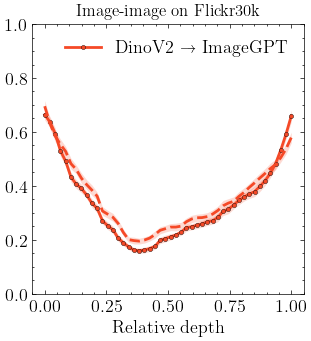

In [23]:
fig, ax = plt.subplots(1, 1, figsize=figsize)
label_forward = f"{MODEL_NAMES['dino']} → {MODEL_NAMES['igpt']}"
ax.plot(x['igpt'], dino_igpt_fwd[0], '-', color=MODEL_COLORS['llama'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['igpt'], dino_igpt_fwd[0] - dino_igpt_fwd[1], dino_igpt_fwd[0] + dino_igpt_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['llama'])
label_backward = f"{MODEL_NAMES['igpt']} → {MODEL_NAMES['dino']}"
ax.plot(x['igpt'], dino_igpt_bwd[0], '--', color=MODEL_COLORS['llama'], linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['igpt'], dino_igpt_bwd[0] - dino_igpt_bwd[1], dino_igpt_bwd[0] + dino_igpt_bwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['llama'])
title = "Image-image on Flickr30k"
ax.set_title(title, fontsize=12)
ax.set_xlabel("Relative depth", fontsize=fontsize_label)
ax.set_ylabel("", fontsize=fontsize_label)
ax.set_ylim(ylim)
ax.tick_params(axis='both', labelsize=fontsize_label)
ax.legend(fontsize=fontsize_label, loc='best')
## ax.grid(True, alpha=0.3)
plt.savefig(Path("/home/masca/GitHub/deepseek-hidden-states/plots/fig4c.pdf"), dpi = 300)
## plt.close()

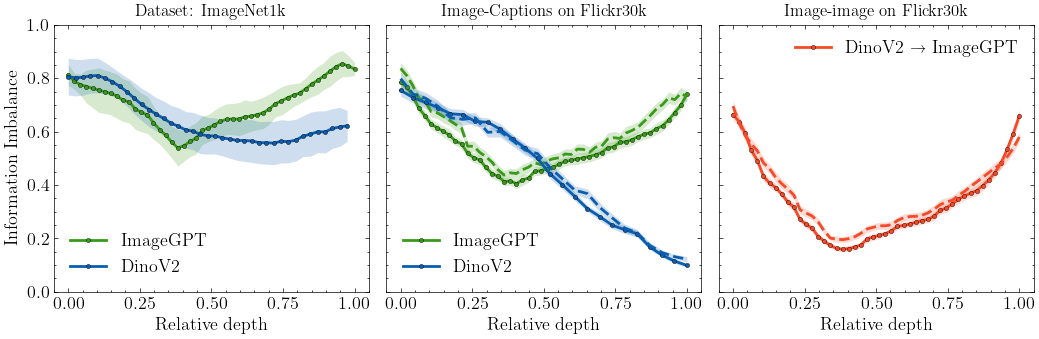

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(figsize[0]*3, figsize[1]), sharey=True)

# Subplot 1: ImageNet1k
ax = axes[0]
label_forward = f"{MODEL_NAMES['igpt']}"
ax.plot(x['igpt'], imagenet_dino_igpt_fwd[0], '-', color=MODEL_COLORS['igpt'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['igpt'], imagenet_dino_igpt_fwd[0] - imagenet_dino_igpt_fwd[1], imagenet_dino_igpt_fwd[0] + imagenet_dino_igpt_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['igpt'])

label_forward = f"{MODEL_NAMES['dino']}"
ax.plot(np.arange(39)/39, imagenet_igpt_dino_fwd[0], '-', color=MODEL_COLORS['dino'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(np.arange(39)/39, imagenet_igpt_dino_fwd[0] - imagenet_igpt_dino_fwd[1], imagenet_igpt_dino_fwd[0] + imagenet_igpt_dino_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])

ax.set_title("Dataset: ImageNet1k", fontsize=12)
ax.set_xlabel("Relative depth", fontsize=fontsize_label)
ax.set_ylabel("Information Imbalance", fontsize=fontsize_label)
ax.tick_params(axis='both', labelsize=fontsize_label)
ax.set_ylim(ylim)
ax.legend(fontsize=fontsize_label, loc='best')

# Subplot 2: Image-Captions on Flickr30k
ax = axes[1]
label_forward = f"{MODEL_NAMES['igpt']}"
ax.plot(x['igpt'], igpt_fwd[0], '-', color=MODEL_COLORS['igpt'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['igpt'], igpt_fwd[0] - igpt_fwd[1], igpt_fwd[0] + igpt_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['igpt'])
label_backward = f"{MODEL_NAMES['igpt']} → {MODEL_NAMES['deepseek']}"
ax.plot(x['igpt'], igpt_bwd[0], '--', color=MODEL_COLORS['igpt'], linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['igpt'], igpt_bwd[0] - igpt_bwd[1], igpt_bwd[0] + igpt_bwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['igpt'])

label_forward = f"{MODEL_NAMES['dino']}"
ax.plot(x['dino'], dino_fwd[0], '-', color=MODEL_COLORS['dino'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['dino'], dino_fwd[0] - dino_fwd[1], dino_fwd[0] + dino_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])
label_backward = f"{MODEL_NAMES['dino']} → {MODEL_NAMES['deepseek']}"
ax.plot(x['dino'], dino_bwd[0], '--', color=MODEL_COLORS['dino'], linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['dino'], dino_bwd[0] - dino_bwd[1], dino_bwd[0] + dino_bwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])

ax.set_title("Image-Captions on Flickr30k", fontsize=12)
ax.set_xlabel("Relative depth", fontsize=fontsize_label)
ax.tick_params(axis='both', labelsize=fontsize_label)
ax.set_ylim(ylim)
ax.legend(fontsize=fontsize_label, loc='best')

# Subplot 3: Image-image on Flickr30k
ax = axes[2]
label_forward = f"{MODEL_NAMES['dino']} → {MODEL_NAMES['igpt']}"
ax.plot(x['igpt'], dino_igpt_fwd[0], '-', color=MODEL_COLORS['llama'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['igpt'], dino_igpt_fwd[0] - dino_igpt_fwd[1], dino_igpt_fwd[0] + dino_igpt_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['llama'])
label_backward = f"{MODEL_NAMES['igpt']} → {MODEL_NAMES['dino']}"
ax.plot(x['igpt'], dino_igpt_bwd[0], '--', color=MODEL_COLORS['llama'], linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['igpt'], dino_igpt_bwd[0] - dino_igpt_bwd[1], dino_igpt_bwd[0] + dino_igpt_bwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['llama'])

ax.set_title("Image-image on Flickr30k", fontsize=12)
ax.set_xlabel("Relative depth", fontsize=fontsize_label)
ax.set_ylim(ylim)
ax.tick_params(axis='both', labelsize=fontsize_label)
ax.legend(fontsize=fontsize_label, loc='best')

plt.tight_layout()
plt.savefig(Path("/home/masca/GitHub/deepseek-hidden-states/plots/figure4.pdf"), dpi=300)

In [24]:
compare_llama = partial(make_comparison, to_model="llama", rng=rng, base_dir=base_dir, hamming=DO_HAMMING)

In [25]:
igpt_fwd_ll, igpt_bwd_ll = compare_llama(from_model="igpt")
dino_fwd_ll, dino_bwd_ll = compare_llama(from_model="dino")

Loading ../data/results-mean/llama_igpt/l2_centered_normalized


Bootstrap layers: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 48/48 [00:00<00:00, 163.14it/s]


Loading ../data/results-mean/llama_dino/l2_centered_normalized


Bootstrap layers: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:00<00:00, 195.24it/s]


In [26]:
clipi_clipt_fwd, clipi_clipt_bwd = make_comparison(to_model="clip_image", from_model="clip_text", rng=rng, n_replicas=n_replicas, bootstrap_size=bootstrap_size, sample_size=sample_size, base_dir=base_dir, hamming=DO_HAMMING)
clipi_dino_fwd, clipi_dino_bwd = make_comparison(to_model="clip_image", from_model="dino", rng=rng, n_replicas=n_replicas, bootstrap_size=bootstrap_size, sample_size=sample_size, base_dir=base_dir, hamming=DO_HAMMING)

Loading ../data/results-mean/clip_image_clip_text/l2_centered_normalized


Bootstrap layers: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [00:00<00:00, 33.52it/s]


Loading ../data/results-mean/clip_image_dino/l2_centered_normalized


Bootstrap layers: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:00<00:00, 35.82it/s]


In [27]:
dino_fwd_base, dino_bwd_base = compare_deepseek(from_model="dino_base")
dino_fwd_small, dino_bwd_small = compare_deepseek(from_model="dino_small")

Loading ../data/results-mean/deepseek_dino_base/l2_centered_normalized


Bootstrap layers: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [00:00<00:00, 201.63it/s]


Loading ../data/results-mean/deepseek_dino_small/l2_centered_normalized


Bootstrap layers: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [00:00<00:00, 199.22it/s]


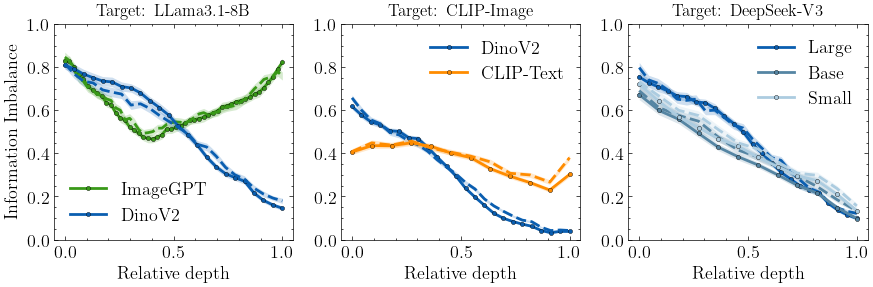

In [28]:
sub_num = 3
fig, axes = plt.subplots(1, sub_num, figsize=(sub_num * figsize[0], 0.8 * figsize[1]))
ylim = (0.0, 1)

ax = axes[0]
label_forward = f"{MODEL_NAMES['igpt']}"
ax.plot(x['igpt'], igpt_fwd_ll[0], '-', color=MODEL_COLORS['igpt'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['igpt'], igpt_fwd_ll[0] - igpt_fwd_ll[1], igpt_fwd_ll[0] + igpt_fwd_ll[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['igpt'])
label_backward = f"{MODEL_NAMES['igpt']} → {MODEL_NAMES['llama']}"
ax.plot(x['igpt'], igpt_bwd_ll[0], '--', color=MODEL_COLORS['igpt'], linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['igpt'], igpt_bwd_ll[0] - igpt_bwd_ll[1], igpt_bwd_ll[0] + igpt_bwd_ll[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['igpt'])

label_forward = f"{MODEL_NAMES['dino']}"
ax.plot(x['dino'], dino_fwd_ll[0], '-', color=MODEL_COLORS['dino'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['dino'], dino_fwd_ll[0] - dino_fwd_ll[1], dino_fwd_ll[0] + dino_fwd_ll[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])
label_backward = f"{MODEL_NAMES['dino']} → {MODEL_NAMES['llama']}"
ax.plot(x['dino'], dino_bwd_ll[0], '--', color=MODEL_COLORS['dino'], linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['dino'], dino_bwd_ll[0] - dino_bwd_ll[1], dino_bwd_ll[0] + dino_bwd_ll[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])

ax.set_xlabel("Relative depth", fontsize=fontsize_label)
ax.set_ylabel("Information Imbalance", fontsize=fontsize_label)
ax.tick_params(axis='both', labelsize=fontsize_label)
ax.set_ylim(ylim)
ax.legend(fontsize=fontsize_label, loc='best')
title = f"Target: {MODEL_NAMES['llama']}"
ax.set_title(f"{title}", fontsize=12)
## ax.grid(True, alpha=0.3)


ax = axes[1]

label_forward = f"{MODEL_NAMES['dino']}"
ax.plot(x['clip_image'], clipi_dino_fwd[0], '-', color=MODEL_COLORS['dino'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['clip_image'], clipi_dino_fwd[0] - clipi_dino_fwd[1], clipi_dino_fwd[0] + clipi_dino_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])
ax.plot(x['dino'], clipi_dino_bwd[0], '--', color=MODEL_COLORS['dino'], linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['clip_image'], clipi_dino_bwd[0] - clipi_dino_bwd[1], clipi_dino_bwd[0] + clipi_dino_bwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])

label_forward = f"{MODEL_NAMES['clip_text']}"
ax.plot(x['clip_text'], clipi_clipt_fwd[0], '-', color=MODEL_COLORS['clip_text'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['clip_text'], clipi_clipt_fwd[0] - clipi_clipt_fwd[1], clipi_clipt_fwd[0] + clipi_clipt_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['clip_text'])
ax.plot(x['clip_text'], clipi_clipt_bwd[0], '--', color=MODEL_COLORS['clip_text'], linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['clip_text'], clipi_clipt_bwd[0] - clipi_clipt_bwd[1], clipi_clipt_bwd[0] + clipi_clipt_bwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['clip_text'])
ax.set_xlabel("Relative depth", fontsize=fontsize_label)
ax.tick_params(axis='both', labelsize=fontsize_label)
ax.set_ylim(ylim)
ax.legend(fontsize=fontsize_label, loc='best')
title = f"Target: {MODEL_NAMES['clip_image']}"
ax.set_title(f"{title}", fontsize=12)

ax = axes[2]
## Dino Large -------
label_forward = f"{MODEL_NAMES['dino']}"
ax.plot(x['dino'], dino_fwd[0], '-', color=MODEL_COLORS['dino'], 
        label="Large", linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['dino'], dino_fwd[0] - dino_fwd[1], dino_fwd[0] + dino_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])

ax.plot(x['dino'], dino_bwd[0], '--', color=MODEL_COLORS['dino'], linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['dino'], dino_bwd[0] - dino_bwd[1], dino_bwd[0] + dino_bwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])
title = f"Target: {MODEL_NAMES['deepseek']}"


## Dino Base --------
ax.plot(x['dino_base'], dino_fwd_base[0], '-', color=MODEL_COLORS['dino_base'], 
        label="Base", linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['dino_base'], dino_fwd_base[0] - dino_fwd_base[1], dino_fwd_base[0] + dino_fwd_base[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino_base'])

ax.plot(x['dino_base'], dino_bwd_base[0], '--', color=MODEL_COLORS['dino_base'], linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['dino_base'], dino_bwd_base[0] - dino_bwd_base[1], dino_bwd_base[0] + dino_bwd_base[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino_base'])
title = f"Target: {MODEL_NAMES['deepseek']}"

## Dino Small ---
ax.plot(x['dino_small'], dino_fwd_small[0], '-', color=MODEL_COLORS['dino_small'], 
        label="Small", linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['dino_base'], dino_fwd_small[0] - dino_fwd_small[1], dino_fwd_small[0] + dino_fwd_small[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino_base'])

ax.plot(x['dino_small'], dino_bwd_small[0], '--', color=MODEL_COLORS['dino_small'], linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['dino_small'], dino_bwd_small[0] - dino_bwd_small[1], dino_bwd_small[0] + dino_bwd_small[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino_small'])
title = f"Target: {MODEL_NAMES['deepseek']}"

ax.set_title(title, fontsize=12)
ax.set_xlabel("Relative depth", fontsize=fontsize_label)
## ax.set_ylabel("Information Imbalance", fontsize=fontsize_label)
ax.tick_params(axis='both', labelsize=fontsize_label)
ax.set_ylim(ylim)
ax.legend(fontsize=fontsize_label, loc='best')

plt.savefig(Path("/home/masca/GitHub/deepseek-hidden-states/plots/fig4_appendix.pdf"), dpi = 300)
#plt.close()